# ECMWF TC Storm Surge Pipeline

This notebook demonstrates the storm surge step (step 5c): from the ECMWF ensemble tracks and 10 m wind
to surge threshold envelopes, in the same format as the wind and gust envelopes.

## Overview

| Step | Module | Output |
|---|---|---|
| 0. Coastal elevation cache (one-time) | `setup_surge_dem` | `surge_coastal_dem.tif`: elevation + distance to coast of low-lying coastal land |
| 2–3. Tracks | `ecmwf_tc_data_extractor`, `ecmwf_tc_data_transformer` | Transformed track CSV |
| 4. Wind | `ecmwf_wind_data_downloader` (here: a local GRIB split into the same files) | `wind_ens_*_pf/cf.grib2` |
| 5c. Surge envelopes | `ecmwf_surge_envelope_extractor` | `*_surge_envelopes_individual.csv`, `*_surge_envelopes_combined.csv` |

## Method

Surge is computed with the CLIMADA `TCSurgeBathtub` method, re-implemented with numpy
(equivalence checked in `tests/test_surge_bathtub.py`):

* surge = 0.1023 × max(V − 26.8224, 0) + 1.8288 − elevation − 0.2 × distance to coast (km), with V the 10 m wind in m/s (Xu 2010)
* computed only on coastal land between 0 and 10 m and within 50 km of the coast, where V ≥ 34 kt
* for each of the 51 members and each lead time, on a 15″ (~450 m) grid

Envelopes are written for 0.5, 1, 2 and 3 m (`surge_threshold` = 50, 100, 200, 300 cm).

## Test case

Hurricane Melissa, Jamaica, ECMWF forecast of 28 October 2025, 00 UTC, lead times 0 to 48 h.
The run uses files already on disk (BUFR tracks, ENS 10 m wind GRIB, SRTM DEM), since ECMWF open data
only keeps the last few days online. For a live cycle, the same step runs inside `github_actions/main.py`
with `PROCESS_SURGE=true`.

## Setup

In [1]:
import os, sys, time, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.features import rasterize
from shapely import wkt

from ecmwf_tc_data_extractor import extract_tc_data, filter_tc_data, save_per_storm_csvs
from ecmwf_tc_data_transformer import transform_tc_data_from_file
from ecmwf_surge_envelope_extractor import process_surge_combination, SURGE_DEM_FILENAME

timings = {}

In [2]:
# ── Inputs already on disk (Part I test data) ──────────────────────────────
DATA = Path("../stormsurge/data")
BUFR_FILE = DATA / "bufr/20251028_00z_tf.bufr"
WIND_GRIB = DATA / "wind/ecmwf_enfo_10uv_20251028_00z_0-48h.grib2"
DEM_FILE  = DATA / "dem/JAM_srtm90.tif"          # existing SRTM 90 m mosaic (GigaSpatial)

STORM = "MELISSA"
RUN_DATE, RUN_HOUR = "2025-10-28", 0
BBOX = (-78.5, 17.6, -76.1, 18.6)                # Jamaica (west, south, east, north)

# ── Working directories (same layout as the pipeline) ─────────────────────
WORK = Path("demo_surge")
directories = {k: WORK / k for k in ("tc_data", "tc_transformed", "wind_data", "wind_extracted", "surge_dem")}
for d in directories.values():
    d.mkdir(parents=True, exist_ok=True)

for f in (BUFR_FILE, WIND_GRIB, DEM_FILE):
    print(f"{'OK     ' if f.exists() else 'MISSING'} {f}")

OK      ../stormsurge/data/bufr/20251028_00z_tf.bufr
OK      ../stormsurge/data/wind/ecmwf_enfo_10uv_20251028_00z_0-48h.grib2
OK      ../stormsurge/data/dem/JAM_srtm90.tif


## Step 0: Coastal elevation cache (one-time)

In production, `setup_surge_dem.py` is run once for the whole SRTM band (56S–60N) and the cache is stored
on the Snowflake stage, like the JRC flood-extent cache. Here it is built for Jamaica only, from the SRTM
mosaic already downloaded (`--dem`), so no Earthdata download is needed.

In [3]:
t0 = time.time()
cmd = [sys.executable, "setup_surge_dem.py",
       "--bbox", *map(str, BBOX),
       "--dem", str(DEM_FILE),
       "--dest-dir", str(WORK / "surge_dem_tmp"),
       "--local-only", str(directories["surge_dem"])]
print(" ".join(cmd))
res = subprocess.run(cmd, capture_output=True, text=True)
print(res.stderr[-2500:])
res.check_returncode()
timings["0_dem_cache"] = time.time() - t0

DEM_CACHE = directories["surge_dem"] / SURGE_DEM_FILENAME
with rasterio.open(DEM_CACHE) as src:
    elev = src.read(1)
    print(f"Cache grid: {src.width} x {src.height}, {src.res[0] * 3600:.0f}\" | "
          f"coastal lowland cells: {np.isfinite(elev).sum():,}")

/opt/anaconda3/envs/stormsurge_env/bin/python setup_surge_dem.py --bbox -78.5 17.6 -76.1 18.6 --dem ../stormsurge/data/dem/JAM_srtm90.tif --dest-dir demo_surge/surge_dem_tmp --local-only demo_surge/surge_dem


2026-10-11 14:08:18,249 - WARNING - CPLE_AppDefined in PROJ: proj_create_from_database: /opt/anaconda3/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 2 whereas a number >= 6 is expected. It comes from another PROJ installation.


2026-10-11 14:08:18,095 - INFO - ======================================================================
2026-10-11 14:08:18,095 - INFO - Storm surge coastal DEM cache setup -- bbox (-78.5, 17.6, -76.1, 18.6), 15" grid
2026-10-11 14:08:18,095 - INFO - Limits: elevation <= 10.0 m, distance to coast <= 50.0 km
2026-10-11 14:08:18,095 - INFO - Elevation: ../stormsurge/data/dem/JAM_srtm90.tif
2026-10-11 14:08:18,095 - INFO - ======================================================================
2026-10-11 14:08:18,096 - INFO -   surge_coastal_dem.tif already built with the same settings -- skipping build
2026-10-11 14:08:18,096 - INFO -   surge_coastal_dem.tif: 0.1 MB
2026-10-11 14:08:18,097 - INFO - Done -- kept locally in demo_surge/surge_dem/surge_coastal_dem.tif (SURGE_DEM_SOURCE=local should point here)

Cache grid: 720 x 480, 15" | coastal lowland cells: 4,769


## Steps 2–3: Tracks (pipeline extractor and transformer)

In [4]:
t0 = time.time()
df = filter_tc_data(extract_tc_data(str(BUFR_FILE), verbose=False), named_storms_only=True)
print("Named storms:", list(df["storm_id"].unique()))
csvs = [p for p in save_per_storm_csvs(df, str(directories["tc_data"]), BUFR_FILE.name, verbose=False)
        if f"_storm_{STORM}_" in Path(p).name]
for p in csvs:
    r = transform_tc_data_from_file(filename=p, output_dir=str(directories["tc_transformed"]), verbose=False)
    print(f"{r['records']} track records -> {Path(r['csv_file']).name}")
timings["2_3_tracks"] = time.time() - t0

Number of Ensemble Members:  52
Number of Ensemble Members:  52
Number of Ensemble Members:  52
Number of Ensemble Members:  52
Number of Ensemble Members:  51
Number of Ensemble Members:  48
Number of Ensemble Members:  40
Number of Ensemble Members:  31
Number of Ensemble Members:  19
Number of Ensemble Members:  13
Number of Ensemble Members:  11
Number of Ensemble Members:  5
Number of Ensemble Members:  1
Number of Ensemble Members:  1
Number of Ensemble Members:  1
Number of Ensemble Members:  49
Number of Ensemble Members:  30
Number of Ensemble Members:  14
Number of Ensemble Members:  5
Number of Ensemble Members:  2
Number of Ensemble Members:  1
Number of Ensemble Members:  52
Number of Ensemble Members:  46
Number of Ensemble Members:  34
Number of Ensemble Members:  19
Number of Ensemble Members:  6
Number of Ensemble Members:  2
Number of Ensemble Members:  1
Number of Ensemble Members:  1
Number of Ensemble Members:  30
Number of Ensemble Members:  15
Number of Ensemble 

## Step 4: Wind

In production, step 4 downloads one GRIB per lead time and per type (`wind_ens_<date>_r<HH>_f<lead>h_pf.grib2`
for the 50 perturbed members, `_cf` for the control). Here the local 0–48 h GRIB is split into exactly those files.

In [5]:
import eccodes

t0 = time.time()
handles = {}
with open(WIND_GRIB, "rb") as f:
    while (gid := eccodes.codes_grib_new_from_file(f)) is not None:
        step = int(eccodes.codes_get(gid, "step"))
        kind = eccodes.codes_get(gid, "dataType")           # "cf" or "pf"
        name = f"wind_ens_{RUN_DATE}_r{RUN_HOUR:02d}_f{step:03d}h_{kind}.grib2"
        if name not in handles:
            handles[name] = open(directories["wind_data"] / name, "wb")
        eccodes.codes_write(gid, handles[name])
        eccodes.codes_release(gid)
for h in handles.values():
    h.close()
timings["4_wind_split"] = time.time() - t0
print(f"{len(handles)} wind files written in {timings['4_wind_split']:.0f} s")

34 wind files written in 3 s


## Step 5c: Surge envelopes

In [6]:
t0 = time.time()
result = process_surge_combination(
    tc_data_dir=directories["tc_transformed"],
    wind_data_dir=directories["wind_data"],
    output_dir=directories["wind_extracted"],
    dem_path=DEM_CACHE,
)
timings["5c_surge"] = time.time() - t0
print(result)

2026-10-11 14:08:23,821 - INFO - ======================================================================
2026-10-11 14:08:23,821 - INFO - ECMWF STORM SURGE ENVELOPE EXTRACTION (bathtub)
2026-10-11 14:08:23,822 - INFO - ======================================================================
2026-10-11 14:08:23,823 - INFO - Found TC data: MELISSA -> 20251028_00z_tf_storm_MELISSA_extracted_transformed.csv
2026-10-11 14:08:23,824 - INFO - 
Surge envelopes for storm: MELISSA
2026-10-11 14:08:23,989 - WARNING - CPLE_AppDefined in PROJ: proj_create_from_database: /opt/anaconda3/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 2 whereas a number >= 6 is expected. It comes from another PROJ installation.
2026-10-11 14:08:24,025 - INFO -   4,769 coastal lowland cells in the storm area
2026-10-11 14:08:25,806 - WARNING - Ignoring index file 'demo_surge/wind_data/wind_ens_2025-10-28_r00_f000h_pf.grib2.5b7b6.idx' older than GRIB file
2026-10-11 14:08:29,639 - WARNING - Ignoring index file 

{'processed_storms': 1, 'total_envelope_files': 2, 'timings': {'MELISSA': 62.5}}


In [7]:
individual = pd.read_csv(next(directories["wind_extracted"].glob(f"{STORM}_*_surge_envelopes_individual.csv")))
combined   = pd.read_csv(next(directories["wind_extracted"].glob(f"{STORM}_*_surge_envelopes_combined.csv")))
print(f"Individual: {len(individual)} records | Combined: {len(combined)} records")

summary = (combined.groupby("surge_threshold")["ensemble_member"].nunique()
           .rename("members reaching threshold").to_frame())
summary["probability"] = (summary.iloc[:, 0] / 51).round(2)
summary.index = [f"{t / 100:g} m" for t in summary.index]
summary

Individual: 838 records | Combined: 156 records


,members reaching threshold,probability
0.5 m,51,1.00
1 m,51,1.00
2 m,42,0.82
3 m,12,0.24


In [8]:
combined.drop(columns="envelope_region").head()

,forecast_time,track_id,ensemble_member,lead_time,surge_threshold
0,2025-10-28,MELISSA,1,0-48,50
1,2025-10-28,MELISSA,1,0-48,100
2,2025-10-28,MELISSA,1,0-48,200
3,2025-10-28,MELISSA,2,0-48,50
4,2025-10-28,MELISSA,2,0-48,100


## Results: probability of surge per cell

What the DATAPIPELINE does with the wind and gust envelopes, applied to the surge envelopes:
each member's combined polygon is rasterized and the probability is the share of the 51 members covering a cell.

2026-10-11 14:09:26,668 - WARNING - CPLE_AppDefined in PROJ: proj_create_from_database: /opt/anaconda3/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 2 whereas a number >= 6 is expected. It comes from another PROJ installation.


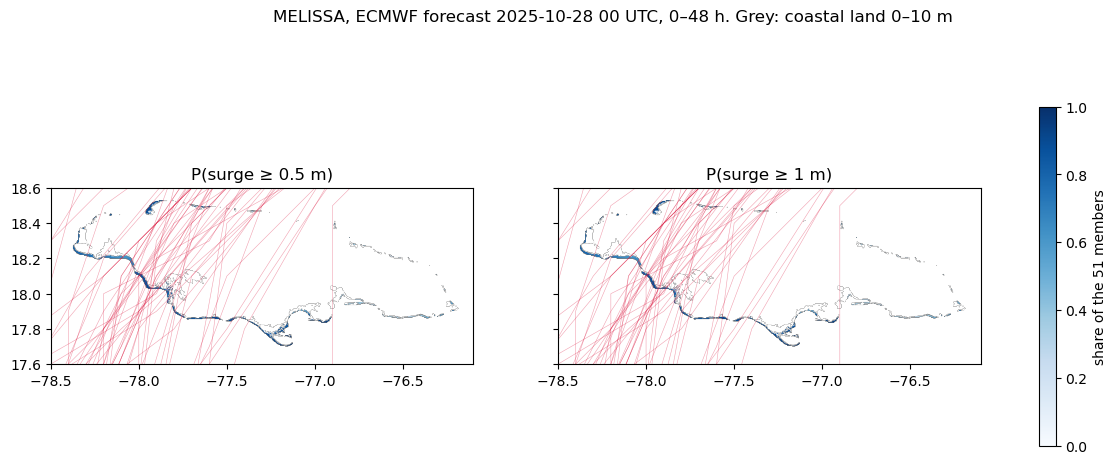

In [9]:
with rasterio.open(DEM_CACHE) as src:
    transform, shape = src.transform, (src.height, src.width)
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
    coastal = np.isfinite(src.read(1))

tracks = pd.read_csv(next(directories["tc_transformed"].glob("*_transformed.csv")))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, thr in zip(axes, (50, 100)):
    sub = combined[combined["surge_threshold"] == thr]
    count = np.zeros(shape, dtype=np.int16)
    for g in sub["envelope_region"]:
        count += rasterize([wkt.loads(g)], out_shape=shape, transform=transform, dtype="uint8")
    prob = np.where(count > 0, count / 51, np.nan)

    ax.imshow(np.where(coastal, 0.0, np.nan), extent=extent, cmap="Greys", vmin=0, vmax=3)
    im = ax.imshow(prob, extent=extent, cmap="Blues", vmin=0, vmax=1)
    for _, t in tracks[tracks["lead_time"] <= 48].sort_values("lead_time").groupby("ensemble_member"):
        ax.plot(t["longitude"], t["latitude"], color="crimson", lw=0.4, alpha=0.4)
    ax.set_xlim(BBOX[0], BBOX[2]); ax.set_ylim(BBOX[1], BBOX[3])
    ax.set_title(f"P(surge ≥ {thr / 100:g} m)")
fig.colorbar(im, ax=axes, shrink=0.8, label="share of the 51 members")
fig.suptitle(f"{STORM}, ECMWF forecast {RUN_DATE} {RUN_HOUR:02d} UTC, 0–48 h. Grey: coastal land 0–10 m", y=0.98)
plt.savefig(WORK / "surge_probability_map.png", dpi=150, bbox_inches="tight")
plt.show()

## Runtime

In [10]:
pd.Series(timings, name="seconds").round(1).to_frame()

,seconds
0_dem_cache,1.1
2_3_tracks,2.5
4_wind_split,3.0
5c_surge,62.5


In production only step 5c runs on each cycle: the elevation cache is built once, and the tracks and wind
are already produced by steps 2–4 for the wind and gust envelopes.